In [1]:
import pandas as pd

df = pd.read_csv("../data/accepted_2007_to_2018Q4.csv", nrows=5000, low_memory=False)
print(df.shape)
print(df["loan_status"].value_counts())

(5000, 151)
loan_status
Fully Paid            3637
Charged Off            816
Current                514
Late (31-120 days)      29
In Grace Period          3
Late (16-30 days)        1
Name: count, dtype: int64


In [3]:
import pandas as pd

file = "../data/accepted_2007_to_2018Q4.csv"

cols = ["id","loan_amnt","funded_amnt","term","int_rate","installment","grade","sub_grade",
        "emp_length","home_ownership","annual_inc","verification_status","issue_d",
        "loan_status","purpose","addr_state","dti","delinq_2yrs","earliest_cr_line",
        "fico_range_low","fico_range_high","open_acc","pub_rec","revol_bal","revol_util",
        "total_acc","total_pymnt"]

keep = ["Fully Paid", "Charged Off", "Default"]
chunks, total = [], 0

for i, chunk in enumerate(pd.read_csv(file, usecols=cols, chunksize=200_000, low_memory=False)):
    chunk = chunk[chunk["loan_status"].isin(keep)]
    chunks.append(chunk)
    total += len(chunk)
    print(f"chunk {i+1} done, kept {total:,} rows", flush=True)

df = pd.concat(chunks, ignore_index=True)
df["is_default"] = df["loan_status"].isin(["Charged Off", "Default"]).astype(int)
print(df.shape)
print("Default rate:", round(df["is_default"].mean() * 100, 2), "%")

chunk 1 done, kept 176,083 rows
chunk 2 done, kept 356,181 rows
chunk 3 done, kept 422,382 rows
chunk 4 done, kept 508,120 rows
chunk 5 done, kept 571,494 rows
chunk 6 done, kept 748,291 rows
chunk 7 done, kept 896,197 rows
chunk 8 done, kept 916,209 rows
chunk 9 done, kept 1,053,648 rows
chunk 10 done, kept 1,229,863 rows
chunk 11 done, kept 1,310,943 rows
chunk 12 done, kept 1,345,350 rows
(1345350, 28)
Default rate: 19.96 %


In [4]:
df.to_csv("../data/loans_subset.csv", index=False)
print("Saved")

Saved


In [5]:
import pandas as pd
df = pd.read_csv("../data/loans_subset.csv", low_memory=False)
print(df.shape)

(1345350, 28)


In [6]:
print(df.groupby("grade")["is_default"].agg(loans="count", default_rate="mean").round(3))

        loans  default_rate
grade                      
A      235095         0.060
B      392748         0.134
C      381694         0.224
D      200966         0.304
E       93656         0.385
F       32059         0.452
G        9132         0.499


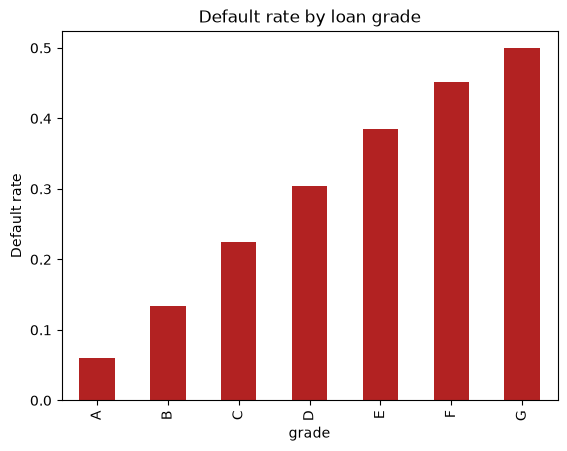

In [7]:
import matplotlib.pyplot as plt
df.groupby("grade")["is_default"].mean().plot(kind="bar", color="firebrick")
plt.title("Default rate by loan grade")
plt.ylabel("Default rate")
plt.show()

In [8]:
print((df.isna().mean() * 100).round(2).sort_values(ascending=False).head(8))

emp_length     5.84
revol_util     0.06
dti            0.03
id             0.00
term           0.00
int_rate       0.00
grade          0.00
installment    0.00
dtype: float64


In [9]:
print(df.groupby("term")["is_default"].agg(["count", "mean"]).round(3))
print(df.groupby("purpose")["is_default"].agg(["count", "mean"]).round(3).sort_values("mean", ascending=False))

df["issue_year"] = pd.to_datetime(df["issue_d"], format="%b-%Y").dt.year
print(df.groupby("issue_year")["is_default"].agg(["count", "mean"]).round(3))

             count   mean
term                     
36 months  1020768  0.160
60 months   324582  0.324
                     count   mean
purpose                          
small_business       15416  0.297
renewable_energy       933  0.237
moving                9480  0.234
house                 7254  0.219
medical              15556  0.218
debt_consolidation  780342  0.211
other                77877  0.210
vacation              9065  0.192
major_purchase       29427  0.186
home_improvement     87507  0.177
educational            326  0.172
credit_card         295285  0.169
car                  14588  0.147
wedding               2294  0.122
             count   mean
issue_year               
2007           251  0.179
2008          1562  0.158
2009          4716  0.126
2010         11536  0.129
2011         21721  0.152
2012         53367  0.162
2013        134804  0.156
2014        223103  0.184
2015        375546  0.202
2016        293105  0.233
2017        169321  0.231
2018         5

In [10]:
df = df[(df["annual_inc"] > 0) & (df["dti"].between(0, 100))].copy()
df["term"] = df["term"].str.strip()
df["fico_avg"] = (df["fico_range_low"] + df["fico_range_high"]) / 2
df["realized_profit"] = df["total_pymnt"] - df["funded_amnt"]

print("Rows after cleaning:", len(df))
df.to_csv("../data/loans_clean.csv", index=False)
print("Saved loans_clean.csv")

Rows after cleaning: 1344441
Saved loans_clean.csv


In [1]:
import sqlite3
import pandas as pd

conn = sqlite3.connect("../data/lending.db")

for i, chunk in enumerate(pd.read_csv("../data/loans_clean.csv", chunksize=200_000, low_memory=False)):
    chunk.to_sql("loans_clean", conn, if_exists="replace" if i == 0 else "append", index=False)
    print(f"chunk {i+1} loaded", flush=True)

conn.execute("CREATE INDEX idx_grade ON loans_clean(grade)")
conn.execute("CREATE INDEX idx_year ON loans_clean(issue_year)")
conn.commit()
print("Done")

chunk 1 loaded
chunk 2 loaded
chunk 3 loaded
chunk 4 loaded
chunk 5 loaded
chunk 6 loaded
chunk 7 loaded
Done


In [2]:
def q(sql):
    return pd.read_sql(sql, conn)

In [3]:
q("""
SELECT COUNT(*) AS loans, ROUND(AVG(is_default), 4) AS default_rate
FROM loans_clean
""")

,loans,default_rate
0,1344441,0.1996


In [4]:
import sqlite3
import pandas as pd
conn = sqlite3.connect("../data/lending.db")
def q(sql):
    return pd.read_sql(sql, conn)

In [5]:
q("""
SELECT grade,
       COUNT(*) AS loans,
       ROUND(100.0 * AVG(is_default), 2) AS default_rate_pct,
       ROUND(AVG(int_rate), 2) AS avg_int_rate,
       ROUND(SUM(realized_profit) / 1000000.0, 1) AS profit_millions
FROM loans_clean
GROUP BY grade
ORDER BY grade
""")

,grade,loans,default_rate_pct,avg_int_rate,profit_millions
0,A,235010,6.04,7.11,176.2
1,B,392532,13.39,10.68,273.5
2,C,381401,22.44,14.02,150.4
3,D,200784,30.38,17.72,16.6
4,E,93570,38.49,21.14,-20.6
5,F,32032,45.21,24.93,-23.8
6,G,9112,49.93,27.72,-16.2


In [6]:
q("""
SELECT grade, term,
       COUNT(*) AS loans,
       ROUND(100.0 * AVG(is_default), 2) AS default_rate_pct,
       ROUND(AVG(realized_profit), 0) AS avg_profit_per_loan
FROM loans_clean
GROUP BY grade, term
ORDER BY grade, term
""")

,grade,term,loans,default_rate_pct,avg_profit_per_loan
0,A,36 months,228726,5.92,750.0
1,A,60 months,6284,10.61,740.0
2,B,36 months,344781,12.75,694.0
3,B,60 months,47751,18.02,716.0
4,C,36 months,275957,20.49,419.0
5,C,60 months,105444,27.54,330.0
6,D,36 months,125968,26.88,156.0
7,D,60 months,74816,36.28,-41.0
8,E,36 months,35997,32.70,-143.0
9,E,60 months,57573,42.11,-268.0


In [7]:
q("""
SELECT CASE WHEN dti < 10 THEN '1) 0-10'
            WHEN dti < 20 THEN '2) 10-20'
            WHEN dti < 30 THEN '3) 20-30'
            ELSE '4) 30+' END AS dti_band,
       COUNT(*) AS loans,
       ROUND(100.0 * AVG(is_default), 2) AS default_rate_pct
FROM loans_clean
GROUP BY 1
ORDER BY 1
""")

,dti_band,loans,default_rate_pct
0,1) 0-10,245721,14.89
1,2) 10-20,561921,17.84
2,3) 20-30,408647,23.04
3,4) 30+,128152,29.18


In [8]:
q("""
SELECT CASE WHEN annual_inc < 40000 THEN '1) <40k'
            WHEN annual_inc < 80000 THEN '2) 40-80k'
            WHEN annual_inc < 120000 THEN '3) 80-120k'
            ELSE '4) 120k+' END AS income_band,
       home_ownership,
       COUNT(*) AS loans,
       ROUND(100.0 * AVG(is_default), 2) AS default_rate_pct
FROM loans_clean
WHERE home_ownership IN ('RENT', 'MORTGAGE', 'OWN')
GROUP BY 1, 2
ORDER BY 1, 2
""")

,income_band,home_ownership,loans,default_rate_pct
0,1) <40k,MORTGAGE,54858,21.23
1,1) <40k,OWN,32714,22.99
2,1) <40k,RENT,121823,25.09
3,2) 40-80k,MORTGAGE,313344,18.57
4,2) 40-80k,OWN,69212,20.87
5,2) 40-80k,RENT,280692,23.61
6,3) 80-120k,MORTGAGE,183928,15.80
7,3) 80-120k,OWN,26683,18.71
8,3) 80-120k,RENT,91079,21.01
9,4) 120k+,MORTGAGE,112858,13.75


In [9]:
q("""
SELECT addr_state,
       COUNT(*) AS loans,
       ROUND(100.0 * AVG(is_default), 2) AS default_rate_pct
FROM loans_clean
GROUP BY addr_state
HAVING COUNT(*) > 5000
ORDER BY default_rate_pct DESC
LIMIT 10
""")

,addr_state,loans,default_rate_pct
0,MS,6584,26.06
1,AR,10037,24.09
2,AL,16604,23.63
3,OK,12268,23.48
4,LA,15487,23.15
5,NY,109816,22.05
6,NV,20246,21.92
7,FL,95554,21.48
8,TN,20365,21.41
9,IN,21698,21.41


In [10]:
q("""
SELECT CASE WHEN fico_avg < 680 THEN '1) <680'
            WHEN fico_avg < 700 THEN '2) 680-699'
            WHEN fico_avg < 720 THEN '3) 700-719'
            WHEN fico_avg < 760 THEN '4) 720-759'
            ELSE '5) 760+' END AS fico_band,
       COUNT(*) AS loans,
       ROUND(100.0 * AVG(is_default), 2) AS default_rate_pct
FROM loans_clean
GROUP BY 1
ORDER BY 1
""")

,fico_band,loans,default_rate_pct
0,1) <680,459257,25.28
1,2) 680-699,361109,21.43
2,3) 700-719,246027,17.29
3,4) 720-759,201119,12.90
4,5) 760+,76929,8.32


In [11]:
q("""
SELECT
  CASE WHEN grade IN ('E','F','G') AND dti > 25 THEN 'Rejected by rule' ELSE 'Approved' END AS decision,
  COUNT(*) AS loans,
  ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM loans_clean), 2) AS pct_of_loans,
  ROUND(100.0 * AVG(is_default), 2) AS default_rate_pct,
  ROUND(SUM(realized_profit) / 1000000.0, 1) AS profit_millions
FROM loans_clean
GROUP BY 1
""")

,decision,loans,pct_of_loans,default_rate_pct,profit_millions
0,Approved,1300833,96.76,19.06,618.3
1,Rejected by rule,43608,3.24,46.95,-62.3


In [12]:
q("""
WITH purpose_stats AS (
    SELECT grade, purpose,
           COUNT(*) AS loans,
           ROUND(AVG(realized_profit), 0) AS avg_profit
    FROM loans_clean
    GROUP BY grade, purpose
    HAVING COUNT(*) > 1000
)
SELECT grade, purpose, loans, avg_profit,
       RANK() OVER (PARTITION BY grade ORDER BY avg_profit DESC) AS profit_rank
FROM purpose_stats
ORDER BY grade, profit_rank
""")

,grade,purpose,loans,avg_profit,profit_rank
0,A,credit_card,74526,880.0,1
1,A,debt_consolidation,115054,805.0,2
2,A,home_improvement,18876,569.0,3
3,A,car,3813,400.0,4
4,A,major_purchase,6709,374.0,5
5,A,other,8954,247.0,6
6,A,medical,2005,142.0,7
7,A,vacation,1172,115.0,8
8,A,small_business,1443,36.0,9
9,B,credit_card,103899,828.0,1


In [13]:
q("""
WITH yearly AS (
    SELECT issue_year,
           COUNT(*) AS loans,
           ROUND(100.0 * AVG(is_default), 2) AS default_rate_pct
    FROM loans_clean
    WHERE issue_year BETWEEN 2012 AND 2017
    GROUP BY issue_year
)
SELECT issue_year, loans, default_rate_pct,
       ROUND(default_rate_pct - LAG(default_rate_pct) OVER (ORDER BY issue_year), 2) AS change_vs_prior_year
FROM yearly
ORDER BY issue_year
""")

,issue_year,loans,default_rate_pct,change_vs_prior_year
0,2012,53367,16.20,NaN
1,2013,134804,15.60,-0.60
2,2014,223103,18.45,2.85
3,2015,375536,20.19,1.74
4,2016,292988,23.28,3.09
5,2017,168851,23.13,-0.15


In [14]:
q("""
SELECT issue_year,
       COUNT(*) AS loans_in_rule_group,
       ROUND(100.0 * AVG(is_default), 1) AS default_rate_pct,
       ROUND(SUM(realized_profit) / 1000000.0, 1) AS profit_millions
FROM loans_clean
WHERE grade IN ('E','F','G') AND dti > 25 AND issue_year BETWEEN 2012 AND 2015
GROUP BY issue_year
ORDER BY issue_year
""")

,issue_year,loans_in_rule_group,default_rate_pct,profit_millions
0,2012,801,35.1,3.6
1,2013,3173,34.4,11.2
2,2014,7290,42.7,4.2
3,2015,13905,49.7,-22.0


In [15]:
q("""
SELECT
  CASE WHEN grade IN ('D','E','F','G') AND term = '60 months' THEN 'Rejected by rule' ELSE 'Approved' END AS decision,
  COUNT(*) AS loans,
  ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM loans_clean), 2) AS pct_of_loans,
  ROUND(100.0 * AVG(is_default), 2) AS default_rate_pct,
  ROUND(SUM(realized_profit) / 1000000.0, 1) AS profit_millions
FROM loans_clean
GROUP BY 1
""")

,decision,loans,pct_of_loans,default_rate_pct,profit_millions
0,Approved,1179704,87.75,17.08,608.8
1,Rejected by rule,164737,12.25,40.62,-52.7


In [16]:
q("""
SELECT grade, term,
       COUNT(*) AS loans,
       ROUND(100.0 * AVG(is_default), 2) AS default_rate_pct,
       ROUND(AVG(realized_profit), 0) AS avg_profit_per_loan
FROM loans_clean
WHERE issue_year BETWEEN 2010 AND 2013
GROUP BY grade, term
ORDER BY grade, term
""")

,grade,term,loans,default_rate_pct,avg_profit_per_loan
0,A,36 months,35930,5.63,968.0
1,A,60 months,1205,8.38,1917.0
2,B,36 months,64516,10.55,1293.0
3,B,60 months,8208,15.58,2886.0
4,C,36 months,38638,15.77,1416.0
5,C,60 months,17772,21.73,3646.0
6,D,36 months,21908,20.23,1416.0
7,D,60 months,10390,27.29,3668.0
8,E,36 months,4569,22.65,1640.0
9,E,60 months,10208,31.17,4323.0


In [17]:
q("""
SELECT issue_year, term,
       COUNT(*) AS loans,
       ROUND(100.0 * AVG(is_default), 1) AS default_rate_pct,
       ROUND(SUM(realized_profit) / 1000000.0, 1) AS profit_millions
FROM loans_clean
WHERE grade IN ('E','F','G') AND dti > 25 AND issue_year BETWEEN 2012 AND 2015
GROUP BY issue_year, term
ORDER BY issue_year, term
""")

,issue_year,term,loans,default_rate_pct,profit_millions
0,2012,36 months,150,24.7,0.4
1,2012,60 months,651,37.5,3.2
2,2013,36 months,732,26.0,0.8
3,2013,60 months,2441,37.0,10.4
4,2014,36 months,2583,32.2,1.6
5,2014,60 months,4707,48.4,2.6
6,2015,36 months,4058,37.9,-0.0
7,2015,60 months,9847,54.6,-21.9


In [18]:
q("""
SELECT grade, term,
       COUNT(*) AS loans,
       ROUND(100.0 * SUM(realized_profit) / SUM(funded_amnt), 1) AS roi_pct,
       ROUND(100.0 * SUM(realized_profit) / SUM(funded_amnt)
             / CASE WHEN term = '36 months' THEN 3.0 ELSE 5.0 END, 1) AS approx_annual_roi_pct
FROM loans_clean
WHERE issue_year BETWEEN 2010 AND 2013
GROUP BY grade, term
ORDER BY grade, term
""")

,grade,term,loans,roi_pct,approx_annual_roi_pct
0,A,36 months,35930,7.8,2.6
1,A,60 months,1205,13.0,2.6
2,B,36 months,64516,10.7,3.6
3,B,60 months,8208,15.8,3.2
4,C,36 months,38638,12.1,4.0
5,C,60 months,17772,19.2,3.8
6,D,36 months,21908,12.5,4.2
7,D,60 months,10390,18.7,3.7
8,E,36 months,4569,13.6,4.5
9,E,60 months,10208,20.4,4.1


In [19]:
q("""
SELECT issue_year,
       COUNT(*) AS loans,
       ROUND(100.0 * AVG(is_default), 1) AS default_rate_pct
FROM loans_clean
WHERE term = '36 months' AND issue_year BETWEEN 2010 AND 2015
GROUP BY issue_year
ORDER BY issue_year
""")

,issue_year,loans,default_rate_pct
0,2010,8466,9.9
1,2011,14101,10.6
2,2012,43470,13.6
3,2013,100422,12.3
4,2014,162570,13.7
5,2015,283019,14.9
